[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/abpandey-dev/learn-python-from-scratch-to-advanced/blob/main/notebooks/02-data-science/02_numpy-ops.ipynb)

*Python for Data Science · Notebook 2 of 8*

# NumPy Operations

Vectorised maths, aggregation along axes, broadcasting, matrix algebra and common numeric recipes.

### 👩‍🏫 From your teacher

**The picture to keep in your head:** Vectorising means telling the whole class to do something at once, instead of asking each student in turn.

**What interviewers really test here:** Broadcasting rules, boolean masks, axis meaning and replacing loops.

### How to use this notebook

1. **Run the setup cell** just below.
2. **Read each lesson slowly.** Work the numbers on paper before reading on.
3. **Run and then change the examples.** Breaking code on purpose is how you learn.
4. **Try each practice question before opening an answer.** If you're stuck, open one hint at a time.
5. **Say your interview answers out loud.** Knowing something and explaining it are different skills.

### Your roadmap

- [ ] 1. Element-wise maths *(Basics)*
- [ ] 2. Aggregations and axes *(Basics)*
- [ ] 3. Understanding axis once and for all *(Basics)*
- [ ] 4. Broadcasting *(Core)*
- [ ] 5. Linear algebra *(Core)*
- [ ] 6. The broadcasting rule, step by step *(Core)*
- [ ] 7. From a loop to one line *(Core)*
- [ ] 8. Handy numeric recipes *(Advanced)*
- [ ] 9. NaN, infinity and float traps *(Advanced)*
- [ ] 10. Random numbers and simulation *(Advanced)*
- [ ] 20 practice questions
- [ ] Interview questions, out loud

In [1]:
# ▶ Run this cell first. It prepares the notebook; you don't need to read it.
import contextlib, copy, io, math, sys
import numpy as np, matplotlib.pyplot as plt
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
PLAIN = True

class ListNode:
    def __init__(self, val=0, next=None):
        self.val, self.next = val, next

class TreeNode:
    def __init__(self, val=0, left=None, right=None):
        self.val, self.left, self.right = val, left, right

def mk_list(vals, pos=-1):
    dummy = cur = ListNode()
    nodes = []
    for v in vals:
        cur.next = ListNode(v)
        cur = cur.next
        nodes.append(cur)
    if pos >= 0 and nodes:
        nodes[-1].next = nodes[pos]
    return dummy.next

def list_arr(head):
    out, seen = [], set()
    while head and id(head) not in seen:
        seen.add(id(head))
        out.append(head.val)
        head = head.next
    return out

def mk_tree(vals):
    if not vals or vals[0] is None:
        return None
    root = TreeNode(vals[0])
    queue, i = [root], 1
    while queue and i < len(vals):
        node = queue.pop(0)
        for side in ("left", "right"):
            if i < len(vals) and vals[i] is not None:
                child = TreeNode(vals[i])
                setattr(node, side, child)
                queue.append(child)
            i += 1
    return root

def tree_arr(root):
    out, queue = [], [root]
    while queue:
        node = queue.pop(0)
        if node:
            out.append(node.val)
            queue += [node.left, node.right]
        else:
            out.append(None)
    while out and out[-1] is None:
        out.pop()
    return out

def find(root, val):
    if not root or root.val == val:
        return root
    return find(root.left, val) or find(root.right, val)

ListNode.__repr__ = lambda self: f"ListNode{list_arr(self)}"
TreeNode.__repr__ = lambda self: f"TreeNode{tree_arr(self)}"

def plain(x, digits=4):
    """NumPy / pandas results as plain Python values, so they compare with a test's expected answer."""
    np = sys.modules.get("numpy")
    pd = sys.modules.get("pandas")
    if pd is not None:
        if isinstance(x, pd.DataFrame):
            return {str(c): plain(x[c].tolist(), digits) for c in x.columns}
        if isinstance(x, pd.Series):
            return {plain(k, digits): plain(v, digits) for k, v in x.items()}
        if isinstance(x, pd.Index):
            return plain(x.tolist(), digits)
        if x is pd.NaT:
            return None
        if isinstance(x, pd.Timestamp):
            return str(x.date()) if x == x.normalize() else str(x)
    if np is not None:
        if isinstance(x, np.ndarray):
            return plain(x.tolist(), digits)
        if isinstance(x, np.generic):
            return plain(x.item(), digits)
    if isinstance(x, float):
        return None if x != x else round(x, digits) + 0.0
    if isinstance(x, list):
        return [plain(v, digits) for v in x]
    if isinstance(x, tuple):
        return tuple(plain(v, digits) for v in x)
    if isinstance(x, dict):
        return {plain(k, digits): plain(v, digits) for k, v in x.items()}
    if isinstance(x, (set, frozenset)):
        return {plain(v, digits) for v in x}
    return x


def check(fn, tests, plain_compare=None, listify=False, design=False, prep=None, post=None,
          norm=None, verify=None, runner=None, inplace=None):
    """Run your code against the tests and show which pass."""
    use_plain = PLAIN if plain_compare is None else plain_compare
    passed, problems = 0, []
    for args, want in tests:
        try:
            a = copy.deepcopy(args)
            if design:
                obj = fn(*a[0])
                got = [getattr(obj, m)(*p) for m, p in a[1]]
            elif runner is not None:
                got = runner(fn, a)
            else:
                if prep is not None:
                    a = prep(a)
                with contextlib.redirect_stdout(io.StringIO()):
                    got = fn(*a)
                if inplace is not None:
                    got = a[inplace]
                if listify:
                    got = list(got)
                if post is not None:
                    got = post(got)
            if verify is not None:
                ok = bool(verify(copy.deepcopy(args), got))
            elif norm is not None:
                ok = norm(copy.deepcopy(got)) == norm(copy.deepcopy(want))
            else:
                ok = (plain(got), plain(want)) if use_plain else (got, want)
                ok = ok[0] == ok[1]
            ok = ok if isinstance(ok, bool) else False
        except Exception as e:  # your code raised an error: report it, don't stop the notebook
            ok, got = False, f"{type(e).__name__}: {e}"
        passed += ok
        if not ok:
            problems.append((args, want, got))
    plt.close("all")
    if passed == len(tests):
        print(f"✅ All {len(tests)} tests passed. Well done! Now compare with the answers below.")
    else:
        print(f"❌ {passed}/{len(tests)} tests passed. First one to fix:")
        args, want, got = problems[0]
        print("   input:   ", repr(args)[:300])
        print("   expected:", repr(want)[:300])
        print("   you got: ", repr(got)[:300])
    return None

print("Ready! Scroll down and start learning.")

Ready! Scroll down and start learning.


---
# Part 1: The theory in one place

Read this once for the big picture. It's fine if it doesn't all stick yet: the lessons will make it concrete, and you can come back to revise.

### Vectorisation

**Vectorisation** means expressing a computation as operations on whole arrays instead of explicit Python loops over elements. NumPy then executes the loop in optimised C (often using CPU SIMD instructions), avoiding per-element interpreter overhead and type checks.



Typical speed-ups over pure Python are 10–100×. Vectorised code is also shorter and closer to the mathematical formula.

### Universal functions (ufuncs)

A **ufunc** is a function that operates element-wise on arrays, supporting broadcasting and type casting.



| Group | Examples |
| --- | --- |
| Arithmetic | `add subtract multiply divide floor_divide mod power negative` (operators `+ - * / // % **`) |
| Comparison | `greater less equal` (operators `> < ==`) → bool arrays |
| Logical | `logical_and logical_or logical_not` (operators `& \| ~`) |
| Maths | `sqrt exp log log10 abs sin cos round floor ceil` |



Ufuncs also have methods: `np.add.reduce` (= sum), `np.add.accumulate` (= cumsum), `np.multiply.outer`.

### Broadcasting rules

1. If the arrays have different numbers of dimensions, prepend 1s to the shape of the smaller one.
2. Two dimensions are compatible when they are equal or one of them is 1.
3. The result's size along each dimension is the maximum of the two; dimensions of size 1 are stretched.
4. If any dimension is incompatible, NumPy raises `ValueError: operands could not be broadcast together`.



| A | B | Result |
| --- | --- | --- |
| (3, 4) | (4,) | (3, 4) |
| (3, 1) | (1, 4) | (3, 4) |
| (5, 1, 3) | (4, 1) | (5, 4, 3) |
| (3, 4) | (3,) | error |

### Aggregations and the axis argument

| Function | NaN-safe version |
| --- | --- |
| `sum, prod` | `nansum, nanprod` |
| `mean, median` | `nanmean, nanmedian` |
| `std, var` (ddof=0 by default) | `nanstd, nanvar` |
| `min, max, argmin, argmax` | `nanmin, nanmax …` |
| `percentile, quantile` | `nanpercentile` |
| `any, all` | — |



`axis=0` collapses rows (result per column); `axis=1` collapses columns (result per row); `keepdims=True` keeps the reduced axis with size 1 so the result broadcasts back against the original.



**ddof**: `std(ddof=0)` is the population standard deviation (divide by n); `ddof=1` is the sample version (divide by n − 1), which pandas uses by default.

### Linear algebra

| Operation | NumPy | Shape rule |
| --- | --- | --- |
| Dot product | `a @ b` | (n,) · (n,) → scalar |
| Matrix product | `A @ B` | (m, k) @ (k, n) → (m, n) |
| Inverse | `np.linalg.inv(A)` | square, non-singular |
| Determinant | `np.linalg.det(A)` | square |
| Solve linear system | `np.linalg.solve(A, b)` | A square; more stable than inv |
| Eigenvalues | `np.linalg.eig(A)` | square |
| Least squares | `np.linalg.lstsq(A, b)` | any |

### Performance tips

- Avoid Python loops over array elements; look for a ufunc, aggregation or broadcasting expression.
- Avoid growing arrays with `np.append` in a loop (it copies every time); collect in a list and convert once, or preallocate with `np.empty`.
- Prefer views (slices) to copies when you don't need independent data.
- Choose smaller dtypes (`float32`, `int32`) for large data when precision allows.
- Use in-place operators (`a += 1`, `np.multiply(a, 2, out=a)`) to save memory.

---
# Part 2: Lessons, step by step

## Lesson 1: Element-wise maths

*Level: Basics*

Arithmetic between arrays of the same shape works **element by element**; arithmetic with a single number applies it to every element:



```python
a = np.array([1, 2, 3])
b = np.array([10, 20, 30])
a + b        # [11 22 33]
a * b        # [10 40 90]   (not a matrix product!)
a ** 2       # [1 4 9]
a / 2        # [0.5 1.  1.5]
```



NumPy's **universal functions** (ufuncs) do the same for maths functions: `np.sqrt, np.exp, np.log, np.abs, np.round, np.sin`…

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

In [2]:
def elementwise_demo():
    a = np.array([1, 2, 3])
    b = np.array([10, 20, 30])
    total = a + b
    product = a * b
    squared = a ** 2
    roots = np.sqrt(b).round(2)
    print(total, product, squared, roots)


elementwise_demo()

[11 22 33] [10 40 90] [1 4 9] [3.16 4.47 5.48]


**✏️ Your turn:** you now have what you need for [Q1](#q1), [Q4](#q4), [Q10](#q10). Try one now, or carry on and do them in Part 3.

## Lesson 2: Aggregations and axes

*Level: Basics*

Aggregations reduce many numbers to one: `sum, mean, median, std, var, min, max, argmin, argmax, prod, cumsum`.



On a 2-D array, `axis` chooses the direction:



```text
m = [[1, 2, 3],
     [4, 5, 6]]
m.sum()         → 21              everything
m.sum(axis=0)   → [5 7 9]         down the rows   (one per column)
m.sum(axis=1)   → [6 15]          across columns  (one per row)
```



Memory trick: the axis you name is the one that **disappears**.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

In [3]:
def axes_demo():
    m = np.array([[1, 2, 3], [4, 5, 6]])
    everything = m.sum()
    per_column = m.sum(axis=0)
    per_row = m.sum(axis=1)
    col_means = m.mean(axis=0)
    print(everything, per_column, per_row, col_means)


axes_demo()

21 [5 7 9] [ 6 15] [2.5 3.5 4.5]


**✏️ Your turn:** you now have what you need for [Q3](#q3), [Q5](#q5), [Q6](#q6), [Q9](#q9). Try one now, or carry on and do them in Part 3.

## Lesson 3: Understanding axis once and for all

*Level: Basics*

`axis` confuses almost everyone at first. Here's the rule: **the axis you name is the one that disappears.**



```python
m = [[1, 2, 3],
     [4, 5, 6]]      # shape (2, 3)
```



| Code | What collapses | Result | Shape |
| --- | --- | --- | --- |
| `m.sum()` | everything | 21 | single value |
| `m.sum(axis=0)` | the rows: adds **down** each column | [5, 7, 9] | (3,) |
| `m.sum(axis=1)` | the columns: adds **across** each row | [6, 15] | (2,) |
| `m.sum(axis=1, keepdims=True)` | same, keeping a column shape | [[6], [15]] | (2, 1) |



#### Why keepdims helps



To turn each row into shares of its total, you need `m / m.sum(axis=1, keepdims=True)`. The result's first row is 1/6, 2/6, 3/6. Without `keepdims`, shapes (2, 3) and (2,) don't line up and you get an error.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

In [4]:
def axis_demo():
    m = np.array([[1, 2, 3], [4, 5, 6]])
    total = m.sum()
    down_columns = m.sum(axis=0)
    across_rows = m.sum(axis=1)
    kept = m.sum(axis=1, keepdims=True)
    shares = (m / kept).round(3)


axis_demo()

**✏️ Your turn:** you now have what you need for [Q5](#q5), [Q6](#q6), [Q3](#q3). Try one now, or carry on and do them in Part 3.

## Lesson 4: Broadcasting

*Level: Core*

**Broadcasting** lets NumPy combine arrays of different shapes by virtually stretching the smaller one. Shapes are compared from the right; two sizes are compatible if they are equal or one of them is 1.



```text
(3, 2) table  +  (2,) row      → row is repeated for each of the 3 rows
(3, 1) column +  (1, 4) row    → (3, 4) grid of every combination
(3, 2)        +  (3,)          → error: 2 vs 3 don't match
```



No data is actually copied, so broadcasting is fast and memory-friendly. It's how you subtract column means, scale features, or build multiplication tables and distance matrices in one line.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

In [5]:
def broadcasting_demo():
    scores = np.array([[70, 80], [60, 90], [80, 70]])
    col_means = scores.mean(axis=0)
    centred = scores - col_means
    col = np.arange(1, 4).reshape(3, 1)
    row = np.arange(1, 5)
    table = col * row
    print(col_means, centred, table, sep="\n")


broadcasting_demo()

[70. 80.]
[[  0.   0.]
 [-10.  10.]
 [ 10. -10.]]
[[ 1  2  3  4]
 [ 2  4  6  8]
 [ 3  6  9 12]]


**✏️ Your turn:** you now have what you need for [Q14](#q14), [Q7](#q7), [Q13](#q13), [Q20](#q20). Try one now, or carry on and do them in Part 3.

## Lesson 5: Linear algebra

*Level: Core*

| Task | Code |
| --- | --- |
| Dot product of vectors | `a @ b` or `np.dot(a, b)` |
| Matrix × matrix / vector | `A @ B`, `A @ v` |
| Transpose | `A.T` |
| Identity | `np.eye(n)` |
| Determinant / inverse | `np.linalg.det(A)`, `np.linalg.inv(A)` |
| Solve A x = b | `np.linalg.solve(A, b)` (better than inv(A) @ b) |
| Vector length | `np.linalg.norm(v)` |



**⚠️ Watch out:** `A * B` multiplies element by element. The matrix product is `A @ B`; their inner dimensions must match.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

In [6]:
def linalg_demo():
    A = np.array([[2, 1], [1, 3]])
    b = np.array([3, 5])
    x = np.linalg.solve(A, b)
    check = A @ x
    elementwise = A * A
    product = A @ A
    print(x.round(2), check, elementwise, product, sep="\n")


linalg_demo()

[0.8 1.4]
[3. 5.]
[[4 1]
 [1 9]]
[[ 5  5]
 [ 5 10]]


**✏️ Your turn:** you now have what you need for [Q2](#q2), [Q15](#q15), [Q8](#q8), [Q18](#q18). Try one now, or carry on and do them in Part 3.

## Lesson 6: The broadcasting rule, step by step

*Level: Core*

Line up the shapes **from the right**. Two sizes are compatible if they're **equal, or one of them is 1**. A missing size counts as 1.



| Shape A | Shape B | Compare from the right | Result |
| --- | --- | --- | --- |
| (3, 2) | a single number | number stretches everywhere | (3, 2) |
| (3, 2) | (2,) | 2 = 2, then 3 vs missing | (3, 2) |
| (3, 1) | (1, 2) | 1 vs 2, then 3 vs 1 | (3, 2) |
| (3, 2) | (3,) | **2 vs 3: neither is 1** | **error** |



#### Fixing the error



To apply one value per **row**, make it a column: `b[:, None]` turns (3,) into (3, 1), and then (3, 2) with (3, 1) works.



#### Worked example: centring columns



`X - X.mean(axis=0)` subtracts a shape (2,) array from (3, 2), so each column loses its own mean, with no loop.



#### Be careful



(3,) with (3, 1) doesn't raise an error. It silently gives a 3 × 3 table, which is a common bug. If a result is unexpectedly large, print the shapes.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

In [7]:
def broadcasting_cases():
    X = np.array([[1, 2], [3, 4], [5, 6]])
    per_column = np.array([10, 20])
    add_columns = X + per_column
    per_row = np.array([1, 2, 3])
    add_rows = X + per_row[:, None]
    surprise = (per_row + per_row[:, None]).shape
    centred = X - X.mean(axis=0)


broadcasting_cases()

**✏️ Your turn:** you now have what you need for [Q14](#q14), [Q7](#q7), [Q20](#q20). Try one now, or carry on and do them in Part 3.

## Lesson 7: From a loop to one line

*Level: Core*

Vectorising means describing the whole operation instead of each step. Use this recipe:



1. Write the loop, and be sure it's correct.
2. Find what's computed per element.
3. Replace `if` with a mask or `np.where`.
4. Replace running totals with `.sum()`, `.cumsum()` or `.mean()`.
5. Test both on a small input.



#### Worked example



Prices above 100 get 10% off, and we want the total.



```python
total = 0                         # loop
for p in prices:
    if p > 100:
        p = p * 0.9
    total += p

np.where(prices > 100, prices * 0.9, prices).sum()   # same result
```



For prices 50, 120, 200: the discounted values are 50, 108, 180, giving a total of 338 both ways.



**Keep the loop when** each step depends on the previous result in a way NumPy has no function for. Clear, correct code beats clever code.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

In [8]:
def vectorise_demo():
    prices = np.array([50.0, 120.0, 200.0])
    loop_total = 0
    for p in prices:
        if p > 100:
            p = p * 0.9
        loop_total += p
    discounted = np.where(prices > 100, prices * 0.9, prices)
    vector_total = discounted.sum()


vectorise_demo()

**✏️ Your turn:** you now have what you need for [Q11](#q11), [Q10](#q10), [Q9](#q9), [Q16](#q16), [Q17](#q17). Try one now, or carry on and do them in Part 3.

## Lesson 8: Handy numeric recipes

*Level: Advanced*

| Need | Recipe |
| --- | --- |
| Differences between neighbours | `np.diff(a)` |
| Percent change | `np.diff(a) / a[:-1] * 100` |
| Moving average | `np.convolve(a, np.ones(k) / k, "valid")` |
| Sort / order of sorting | `np.sort(a)`, `a.argsort()` |
| Count integers 0…k | `np.bincount(a)` |
| Random numbers (repeatable) | `rng = np.random.default_rng(42); rng.normal(0, 1, 100)` |
| Missing values | `np.nan`, `np.isnan(a)`, `np.nanmean(a)` |



The rule behind every optimal answer in this topic: **replace Python loops with whole-array operations**.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

In [9]:
def recipes_demo():
    prices = np.array([100.0, 110.0, 99.0, 121.0])
    change = np.diff(prices)
    pct = (change / prices[:-1] * 100).round(1)
    smooth = np.convolve(prices, np.ones(2) / 2, mode="valid")
    with_gap = np.array([1.0, np.nan, 3.0])
    print(pct, smooth, np.nanmean(with_gap))


recipes_demo()

[ 10.  -10.   22.2] [105.  104.5 110. ] 2.0


**✏️ Your turn:** you now have what you need for [Q16](#q16), [Q17](#q17), [Q12](#q12), [Q19](#q19), [Q11](#q11). Try one now, or carry on and do them in Part 3.

## Lesson 9: NaN, infinity and float traps

*Level: Advanced*

| Code | Result | Why |
| --- | --- | --- |
| `0.1 + 0.2 == 0.3` | False | binary floats can't hold 0.1 exactly |
| `np.isclose(0.1 + 0.2, 0.3)` | True | the right way to compare floats |
| `np.nan == np.nan` | False | NaN never equals anything; use `np.isnan` |
| `np.array([1, np.nan]).mean()` | nan | one NaN poisons the result |
| `np.nanmean([1, np.nan])` | 1.0 | ignores NaN |
| `np.array([1.0]) / 0` | inf, with a warning | no exception is raised |



**Debugging tip:** when results become NaN, find the first one: `np.isnan(a).any()` and `np.isinf(a).any()`. Common sources are dividing by zero and the log of 0 or of a negative number.



Unlike pandas, NumPy's plain `mean` and `sum` don't skip NaN.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

In [10]:
def nan_traps():
    float_equal = 0.1 + 0.2 == 0.3
    float_close = bool(np.isclose(0.1 + 0.2, 0.3))
    nan_equal = np.nan == np.nan
    with_gap = np.array([1.0, np.nan, 3.0])
    plain_mean = with_gap.mean()
    skip_mean = np.nanmean(with_gap)
    gaps = np.isnan(with_gap)


nan_traps()

**✏️ Your turn:** you now have what you need for [Q3](#q3), [Q13](#q13). Try one now, or carry on and do them in Part 3.

## Lesson 10: Random numbers and simulation

*Level: Advanced*

NumPy can simulate what's hard to calculate. Always create a generator with a **seed**, so the results can be repeated:



```python
rng = np.random.default_rng(42)
rng.integers(1, 7, size=5)      # dice rolls (the top value is excluded)
rng.normal(0, 1, size=1000)     # bell curve
rng.choice(items, size=3)       # pick randomly
rng.permutation(10)             # shuffle
```



#### Worked example: dice



The true average of a die is 3.5. The chart rolls more and more dice: the running average wobbles at first and then settles at 3.5. That's the **law of large numbers**, and it's why more data gives more stable estimates.



**Common mistake:** `rng.integers(1, 6)` never gives a 6, since the top is excluded.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

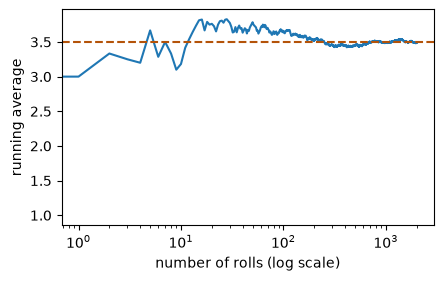

In [11]:
def dice_simulation():
    rng = np.random.default_rng(42)
    rolls = rng.integers(1, 7, size=2000)
    running = rolls.cumsum() / np.arange(1, 2001)
    final_average = running[-1]
    fig, ax = plt.subplots(figsize=(4.8, 2.8))
    ax.plot(running)
    ax.axhline(3.5, ls="--", color="#b45309")
    ax.set_xscale("log")
    ax.set_xlabel("number of rolls (log scale)")
    ax.set_ylabel("running average")


dice_simulation()

**✏️ Your turn:** you now have what you need for [Q12](#q12). Try one now, or carry on and do them in Part 3.

---
# Part 3: Practice like an interview

There are 20 questions here, easiest first.

**Work the way you would in a real interview:** restate the problem, try an example by hand, say the simple approach and its cost, improve it, then write the code. Test it with the cell. Only open an answer once you've made a real attempt, because struggling is where the learning happens.

<a id="q1"></a>
### Q1. Add Two Lists Element by Element

🟢 Warm-up · *Element-wise +*

Return [a[0] + b[0], a[1] + b[1], …].

**Examples**

- `a = [1, 2, 3], b = [10, 20, 30]` → `[11, 22, 33]`
- `a = [], b = []` → `[]`

In [ ]:
def add_lists(a, b):
    """
    Return [a[0] + b[0], a[1] + b[1], …].
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(add_lists, [
    (([1, 2, 3], [10, 20, 30]), [11, 22, 33]),
    (([], []), []),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Loop over the indices.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Arrays add element by element: `np.array(a) + np.array(b)`.

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** Loop over the indices.

```python
def add_lists(a, b):
    out = []
    for i in range(len(a)):
        out.append(a[i] + b[i])
    return out
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** Arrays add element by element: `np.array(a) + np.array(b)`.

```python
def add_lists(a, b):
    return np.array(a) + np.array(b)
```

**Cost:** O(n) vectorised time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Loop over the indices. That costs O(n) time and O(n) space."

"I can do better: Arrays add element by element: `np.array(a) + np.array(b)`. That's O(n) vectorised time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/numpy-ops/add-two-lists-element-by-element)

<a id="q2"></a>
### Q2. Dot Product

🟢 Warm-up · *@ / np.dot*

Return the dot product Σ a[i] × b[i].

**Examples**

- `a = [1, 2, 3], b = [4, 5, 6]` → `32`
- `a = [2], b = [5]` → `10`

In [ ]:
def dot(a, b):
    """
    Return the dot product Σ a[i] × b[i].
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(dot, [
    (([1, 2, 3], [4, 5, 6]), 32),
    (([2], [5]), 10),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Multiply pairs in a loop and add.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.dot(a, b)` or `a @ b`.

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** Multiply pairs in a loop and add.

```python
def dot(a, b):
    total = 0
    for x, y in zip(a, b):
        total += x * y
    return total
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** `np.dot(a, b)` or `a @ b`.

```python
def dot(a, b):
    return np.array(a) @ np.array(b)
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Multiply pairs in a loop and add. That costs O(n) time and O(1) space."

"I can do better: `np.dot(a, b)` or `a @ b`. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/numpy-ops/dot-product)

<a id="q3"></a>
### Q3. Mean and Standard Deviation

🟢 Warm-up · *Aggregations*

Return `(mean, standard deviation)` rounded to 2 decimals (population std).

**Examples**

- `nums = [2, 4, 4, 4, 5, 5, 7, 9]` → `(5.0, 2.0)`
- `nums = [10, 10]` → `(10.0, 0.0)`

In [ ]:
def mean_std(nums):
    """
    Return (mean, standard deviation) rounded to 2 decimals (population std).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(mean_std, [
    (([2, 4, 4, 4, 5, 5, 7, 9],), (5.0, 2.0)),
    (([10, 10],), (10.0, 0.0)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Compute the mean, then the average squared distance from it, then the square root.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`arr.mean()` and `arr.std()`.

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** Compute the mean, then the average squared distance from it, then the square root.

```python
def mean_std(nums):
    mean = sum(nums) / len(nums)
    squares = 0
    for x in nums:
        squares += (x - mean) ** 2
    std = (squares / len(nums)) ** 0.5
    return (round(mean, 2), round(std, 2))
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** `arr.mean()` and `arr.std()`.

```python
def mean_std(nums):
    arr = np.array(nums)
    return (round(arr.mean(), 2), round(arr.std(), 2))
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Compute the mean, then the average squared distance from it, then the square root. That costs O(n) time and O(1) space."

"I can do better: `arr.mean()` and `arr.std()`. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/numpy-ops/mean-and-standard-deviation)

<a id="q4"></a>
### Q4. Scale to 0–1 (Min-Max)

🟢 Warm-up · *Vectorised formula*

Rescale numbers so the smallest becomes 0 and the largest 1: (x − min) / (max − min), rounded to 2 decimals.

**Examples**

- `nums = [10, 20, 15, 30]` → `[0.0, 0.5, 0.25, 1.0]`
- `nums = [5, 7]` → `[0.0, 1.0]`

In [ ]:
def min_max_scale(nums):
    """
    Rescale numbers so the smallest becomes 0 and the largest 1: (x − min) /
    (max − min), rounded to 2 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(min_max_scale, [
    (([10, 20, 15, 30],), [0.0, 0.5, 0.25, 1.0]),
    (([5, 7],), [0.0, 1.0]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Find min and max, then apply the formula in a loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Write the formula once on the whole array.

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** Find min and max, then apply the formula in a loop.

```python
def min_max_scale(nums):
    lo, hi = min(nums), max(nums)
    out = []
    for x in nums:
        out.append(round((x - lo) / (hi - lo), 2))
    return out
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** Write the formula once on the whole array.

```python
def min_max_scale(nums):
    a = np.array(nums, dtype=float)
    return ((a - a.min()) / (a.max() - a.min())).round(2)
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Find min and max, then apply the formula in a loop. That costs O(n) time and O(n) space."

"I can do better: Write the formula once on the whole array. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/numpy-ops/scale-to-0-1-min-max)

<a id="q5"></a>
### Q5. Row Totals

🟢 Warm-up · *sum(axis=1)*

Return the sum of each row of a table.

**Examples**

- `table = [[1, 2, 3], [4, 5, 6]]` → `[6, 15]`
- `table = [[7]]` → `[7]`

In [ ]:
def row_totals(table):
    """
    Return the sum of each row of a table.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(row_totals, [
    (([[1, 2, 3], [4, 5, 6]],), [6, 15]),
    (([[7]],), [7]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Loop over rows and add each row.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`m.sum(axis=1)` adds across the columns.

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** Loop over rows and add each row.

```python
def row_totals(table):
    out = []
    for row in table:
        total = 0
        for x in row:
            total += x
        out.append(total)
    return out
```

**Cost:** O(n) time, O(rows) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** `m.sum(axis=1)` adds across the columns.

```python
def row_totals(table):
    return np.array(table).sum(axis=1)
```

**Cost:** O(n) time, O(rows) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Loop over rows and add each row. That costs O(n) time and O(rows) space."

"I can do better: `m.sum(axis=1)` adds across the columns. That's O(n) time and O(rows) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/numpy-ops/row-totals)

<a id="q6"></a>
### Q6. Column Averages

🟢 Warm-up · *mean(axis=0)*

Return the average of each column, rounded to 2 decimals.

**Examples**

- `table = [[1, 2], [3, 5], [5, 8]]` → `[3.0, 5.0]`
- `table = [[4, 9]]` → `[4.0, 9.0]`

In [ ]:
def column_means(table):
    """
    Return the average of each column, rounded to 2 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(column_means, [
    (([[1, 2], [3, 5], [5, 8]],), [3.0, 5.0]),
    (([[4, 9]],), [4.0, 9.0]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Loop over columns, then rows.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`m.mean(axis=0)` averages down the rows.

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** Loop over columns, then rows.

```python
def column_means(table):
    cols = len(table[0])
    out = []
    for c in range(cols):
        total = 0
        for row in table:
            total += row[c]
        out.append(round(total / len(table), 2))
    return out
```

**Cost:** O(n) time, O(cols) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** `m.mean(axis=0)` averages down the rows.

```python
def column_means(table):
    return np.array(table).mean(axis=0).round(2)
```

**Cost:** O(n) time, O(cols) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Loop over columns, then rows. That costs O(n) time and O(cols) space."

"I can do better: `m.mean(axis=0)` averages down the rows. That's O(n) time and O(cols) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/numpy-ops/column-averages)

<a id="q7"></a>
### Q7. Multiplication Table

🟢 Warm-up · *Outer product*

Return the n × n table where cell (i, j) = (i + 1) × (j + 1).

**Examples**

- `n = 3` → `[[1, 2, 3], [2, 4, 6], [3, 6, 9]]`

In [ ]:
def times_table(n):
    """
    Return the n × n table where cell (i, j) = (i + 1) × (j + 1).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(times_table, [
    ((3,), [[1, 2, 3], [2, 4, 6], [3, 6, 9]]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Nested loops.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Broadcast a column against a row: `col * row` (or `np.outer`).

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** Nested loops.

```python
def times_table(n):
    return [[(i + 1) * (j + 1) for j in range(n)] for i in range(n)]
```

**Cost:** O(n²) time, O(n²) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** Broadcast a column against a row: `col * row` (or `np.outer`).

```python
def times_table(n):
    v = np.arange(1, n + 1)
    return v[:, np.newaxis] * v
```

**Cost:** O(n²) time, O(n²) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Nested loops. That costs O(n²) time and O(n²) space."

"I can do better: Broadcast a column against a row: `col * row` (or `np.outer`). That's O(n²) time and O(n²) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/numpy-ops/multiplication-table)

<a id="q8"></a>
### Q8. Transpose

🟢 Warm-up · *.T*

Swap rows and columns.

**Examples**

- `table = [[1, 2, 3], [4, 5, 6]]` → `[[1, 4], [2, 5], [3, 6]]`

In [ ]:
def transpose(table):
    """
    Swap rows and columns.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(transpose, [
    (([[1, 2, 3], [4, 5, 6]],), [[1, 4], [2, 5], [3, 6]]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Nested loops reading down each column.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`m.T` — a view, no copying.

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** Nested loops reading down each column.

```python
def transpose(table):
    return [[table[r][c] for r in range(len(table))] for c in range(len(table[0]))]
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** `m.T` — a view, no copying.

```python
def transpose(table):
    return np.array(table).T
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Nested loops reading down each column. That costs O(n) time and O(n) space."

"I can do better: `m.T` — a view, no copying. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/numpy-ops/transpose)

<a id="q9"></a>
### Q9. Running Total

🟢 Warm-up · *cumsum*

Return the running totals of the numbers.

**Examples**

- `nums = [1, 2, 3, 4]` → `[1, 3, 6, 10]`
- `nums = []` → `[]`

In [ ]:
def running_total(nums):
    """
    Return the running totals of the numbers.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(running_total, [
    (([1, 2, 3, 4],), [1, 3, 6, 10]),
    (([],), []),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Keep a total and append it each step.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.cumsum`.

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** Keep a total and append it each step.

```python
def running_total(nums):
    out, total = [], 0
    for x in nums:
        total += x
        out.append(total)
    return out
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** `np.cumsum`.

```python
def running_total(nums):
    return np.cumsum(nums)
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Keep a total and append it each step. That costs O(n) time and O(n) space."

"I can do better: `np.cumsum`. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/numpy-ops/running-total)

<a id="q10"></a>
### Q10. Clip to a Range

🟢 Warm-up · *np.clip*

Limit every number to the range [lo, hi].

**Examples**

- `nums = [-5, 3, 12, 7], lo = 0, hi = 10` → `[0, 3, 10, 7]`

In [ ]:
def clip(nums, lo, hi):
    """
    Limit every number to the range [lo, hi].
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(clip, [
    (([-5, 3, 12, 7], 0, 10), [0, 3, 10, 7]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

min/max per element in a loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.clip(arr, lo, hi)`.

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** min/max per element in a loop.

```python
def clip(nums, lo, hi):
    return [max(lo, min(x, hi)) for x in nums]
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** `np.clip(arr, lo, hi)`.

```python
def clip(nums, lo, hi):
    return np.clip(nums, lo, hi)
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: min/max per element in a loop. That costs O(n) time and O(n) space."

"I can do better: `np.clip(arr, lo, hi)`. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/numpy-ops/clip-to-a-range)

<a id="q11"></a>
### Q11. Keep the Even Numbers

🟢 Warm-up · *Mask filtering*

Return only the even numbers.

**Examples**

- `nums = [1, 2, 3, 4, 6]` → `[2, 4, 6]`
- `nums = [1, 3]` → `[]`

In [ ]:
def evens(nums):
    """
    Return only the even numbers.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(evens, [
    (([1, 2, 3, 4, 6],), [2, 4, 6]),
    (([1, 3],), []),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Loop with an if.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`a[a % 2 == 0]`.

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** Loop with an if.

```python
def evens(nums):
    return [x for x in nums if x % 2 == 0]
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** `a[a % 2 == 0]`.

```python
def evens(nums):
    a = np.array(nums, dtype=int)
    return a[a % 2 == 0]
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Loop with an if. That costs O(n) time and O(n) space."

"I can do better: `a[a % 2 == 0]`. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/numpy-ops/keep-the-even-numbers)

<a id="q12"></a>
### Q12. Count Each Value

🟢 Warm-up · *np.bincount*

Dice rolls are numbers 1–6. Return how many times each face 1…6 appeared.

**Examples**

- `rolls = [1, 6, 6, 2, 1, 6]` → `[2, 1, 0, 0, 0, 3]`
- `rolls = []` → `[0, 0, 0, 0, 0, 0]`

In [ ]:
def face_counts(rolls):
    """
    Dice rolls are numbers 1–6. Return how many times each face 1…6 appeared.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(face_counts, [
    (([1, 6, 6, 2, 1, 6],), [2, 1, 0, 0, 0, 3]),
    (([],), [0, 0, 0, 0, 0, 0]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

A list of 6 counters updated in a loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.bincount(rolls, minlength=7)[1:]`.

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** A list of 6 counters updated in a loop.

```python
def face_counts(rolls):
    counts = [0] * 6
    for r in rolls:
        counts[r - 1] += 1
    return counts
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** `np.bincount(rolls, minlength=7)[1:]`.

```python
def face_counts(rolls):
    return np.bincount(np.array(rolls, dtype=int), minlength=7)[1:]
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: A list of 6 counters updated in a loop. That costs O(n) time and O(1) space."

"I can do better: `np.bincount(rolls, minlength=7)[1:]`. That's O(n) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/numpy-ops/count-each-value)

<a id="q13"></a>
### Q13. Z-Scores

🟡 Interview standard · *Standardisation*

Return each value's z-score (x − mean) / std, rounded to 2 decimals.

**Examples**

- `nums = [2, 4, 4, 4, 5, 5, 7, 9]` → `[-1.5, -0.5, -0.5, -0.5, 0.0, 0.0, 1.0, 2.0]`

In [ ]:
def z_scores(nums):
    """
    Return each value's z-score (x − mean) / std, rounded to 2 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(z_scores, [
    (([2, 4, 4, 4, 5, 5, 7, 9],), [-1.5, -0.5, -0.5, -0.5, 0.0, 0.0, 1.0, 2.0]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Compute mean and std by hand, then loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`(a - a.mean()) / a.std()`.

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** Compute mean and std by hand, then loop.

```python
def z_scores(nums):
    n = len(nums)
    mean = sum(nums) / n
    std = (sum((x - mean) ** 2 for x in nums) / n) ** 0.5
    return [round((x - mean) / std, 2) for x in nums]
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** `(a - a.mean()) / a.std()`.

```python
def z_scores(nums):
    a = np.array(nums, dtype=float)
    return ((a - a.mean()) / a.std()).round(2)
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Compute mean and std by hand, then loop. That costs O(n) time and O(n) space."

"I can do better: `(a - a.mean()) / a.std()`. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/numpy-ops/z-scores)

<a id="q14"></a>
### Q14. Add a Row to Every Row

🟡 Interview standard · *Broadcasting*

Add the list `row` to every row of `table`.

**Examples**

- `table = [[1, 2], [3, 4]], row = [10, 100]` → `[[11, 102], [13, 104]]`

In [ ]:
def add_row(table, row):
    """
    Add the list row to every row of table.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(add_row, [
    (([[1, 2], [3, 4]], [10, 100]), [[11, 102], [13, 104]]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Nested loops adding row[c] to every cell.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Broadcasting stretches the 1-D row across all rows: `m + row`.

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** Nested loops adding row[c] to every cell.

```python
def add_row(table, row):
    out = []
    for r in table:
        out.append([r[c] + row[c] for c in range(len(row))])
    return out
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** Broadcasting stretches the 1-D row across all rows: `m + row`.

```python
def add_row(table, row):
    return np.array(table) + np.array(row)
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Nested loops adding row[c] to every cell. That costs O(n) time and O(n) space."

"I can do better: Broadcasting stretches the 1-D row across all rows: `m + row`. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/numpy-ops/add-a-row-to-every-row)

<a id="q15"></a>
### Q15. Matrix Multiplication

🟡 Interview standard · *@ operator*

Multiply matrix A (m × k) by matrix B (k × n).

**Examples**

- `A = [[1, 2], [3, 4]], B = [[5, 6], [7, 8]]` → `[[19, 22], [43, 50]]`
- `A = [[1, 2, 3]], B = [[1], [1], [1]]` → `[[6]]`

In [ ]:
def matmul(A, B):
    """
    Multiply matrix A (m × k) by matrix B (k × n).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(matmul, [
    (([[1, 2], [3, 4]], [[5, 6], [7, 8]]), [[19, 22], [43, 50]]),
    (([[1, 2, 3]], [[1], [1], [1]]), [[6]]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Three nested loops: row of A times column of B.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`A @ B` — optimised BLAS code.

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** Three nested loops: row of A times column of B.

```python
def matmul(A, B):
    m, k, n = len(A), len(B), len(B[0])
    C = [[0] * n for _ in range(m)]
    for i in range(m):
        for j in range(n):
            for t in range(k):
                C[i][j] += A[i][t] * B[t][j]
    return C
```

**Cost:** O(m·k·n) in Python time, O(m·n) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** `A @ B` — optimised BLAS code.

```python
def matmul(A, B):
    return np.array(A) @ np.array(B)
```

**Cost:** O(m·k·n) in C time, O(m·n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Three nested loops: row of A times column of B. That costs O(m·k·n) in Python time and O(m·n) space."

"I can do better: `A @ B` — optimised BLAS code. That's O(m·k·n) in C time and O(m·n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/numpy-ops/matrix-multiplication)

<a id="q16"></a>
### Q16. Moving Average

🟡 Interview standard · *cumsum trick / convolve*

Return the average of every window of k consecutive numbers, rounded to 2 decimals.

**Examples**

- `nums = [1, 2, 3, 4, 5], k = 2` → `[1.5, 2.5, 3.5, 4.5]`
- `nums = [10, 20, 30], k = 3` → `[20.0]`

In [ ]:
def moving_average(nums, k):
    """
    Return the average of every window of k consecutive numbers, rounded to 2
    decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(moving_average, [
    (([1, 2, 3, 4, 5], 2), [1.5, 2.5, 3.5, 4.5]),
    (([10, 20, 30], 3), [20.0]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Average each window from scratch.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.convolve(a, np.ones(k) / k, mode='valid')` slides the window for you.

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** Average each window from scratch.

```python
def moving_average(nums, k):
    out = []
    for i in range(len(nums) - k + 1):
        window = nums[i:i + k]
        out.append(round(sum(window) / k, 2))
    return out
```

**Cost:** O(n·k) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** `np.convolve(a, np.ones(k) / k, mode='valid')` slides the window for you.

```python
def moving_average(nums, k):
    return np.convolve(nums, np.ones(k) / k, mode="valid").round(2)
```

**Cost:** O(n·k) in C time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Average each window from scratch. That costs O(n·k) time and O(n) space."

"I can do better: `np.convolve(a, np.ones(k) / k, mode='valid')` slides the window for you. That's O(n·k) in C time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/numpy-ops/moving-average)

<a id="q17"></a>
### Q17. Day-to-Day Percent Change

🟡 Interview standard · *np.diff*

Given daily prices, return the percent change from each day to the next, rounded to 1 decimal.

**Examples**

- `prices = [100, 110, 99]` → `[10.0, -10.0]`
- `prices = [50, 50]` → `[0.0]`

In [ ]:
def pct_change(prices):
    """
    Given daily prices, return the percent change from each day to the next,
    rounded to 1 decimal.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(pct_change, [
    (([100, 110, 99],), [10.0, -10.0]),
    (([50, 50],), [0.0]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Loop over neighbouring pairs.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.diff(p) / p[:-1] * 100` — every pair at once.

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** Loop over neighbouring pairs.

```python
def pct_change(prices):
    out = []
    for i in range(1, len(prices)):
        out.append(round((prices[i] - prices[i - 1]) / prices[i - 1] * 100, 1))
    return out
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** `np.diff(p) / p[:-1] * 100` — every pair at once.

```python
def pct_change(prices):
    p = np.array(prices, dtype=float)
    return (np.diff(p) / p[:-1] * 100).round(1)
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Loop over neighbouring pairs. That costs O(n) time and O(n) space."

"I can do better: `np.diff(p) / p[:-1] * 100` — every pair at once. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/numpy-ops/day-to-day-percent-change)

<a id="q18"></a>
### Q18. Solve Two Equations

🟡 Interview standard · *np.linalg.solve*

Solve a·x + b·y = e and c·x + d·y = f. Input is [[a, b], [c, d]] and [e, f]; return [x, y] rounded to 2 decimals.

**Examples**

- `A = [[2, 1], [1, 3]], b = [3, 5]` → `[0.8, 1.4]`
- `A = [[1, 0], [0, 1]], b = [4, 7]` → `[4.0, 7.0]`

In [ ]:
def solve2(A, b):
    """
    Solve a·x + b·y = e and c·x + d·y = f. Input is [[a, b], [c, d]] and [e, f];
    return [x, y] rounded to 2 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(solve2, [
    (([[2, 1], [1, 3]], [3, 5]), [0.8, 1.4]),
    (([[1, 0], [0, 1]], [4, 7]), [4.0, 7.0]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Cramer's rule with determinants by hand.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.linalg.solve(A, b)` works for any size n × n system.

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** Cramer's rule with determinants by hand.

```python
def solve2(A, b):
    (a1, b1), (c1, d1) = A
    e, f = b
    det = a1 * d1 - b1 * c1
    x = (e * d1 - b1 * f) / det
    y = (a1 * f - e * c1) / det
    return [round(x, 2), round(y, 2)]
```

**Cost:** O(1) for 2×2 time, O(1) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** `np.linalg.solve(A, b)` works for any size n × n system.

```python
def solve2(A, b):
    return np.linalg.solve(np.array(A, dtype=float), np.array(b, dtype=float)).round(2)
```

**Cost:** O(n³) time, O(n²) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Cramer's rule with determinants by hand. That costs O(1) for 2×2 time and O(1) space."

"I can do better: `np.linalg.solve(A, b)` works for any size n × n system. That's O(n³) time and O(n²) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/numpy-ops/solve-two-equations)

<a id="q19"></a>
### Q19. Sort Rows by a Column

🟡 Interview standard · *argsort*

Sort the rows of a table by the values in column `c` (ascending).

**Examples**

- `table = [[3, 9], [1, 7], [2, 8]], c = 0` → `[[1, 7], [2, 8], [3, 9]]`
- `table = [[5, 1], [4, 2]], c = 1` → `[[5, 1], [4, 2]]`

In [ ]:
def sort_rows(table, c):
    """
    Sort the rows of a table by the values in column c (ascending).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(sort_rows, [
    (([[3, 9], [1, 7], [2, 8]], 0), [[1, 7], [2, 8], [3, 9]]),
    (([[5, 1], [4, 2]], 1), [[5, 1], [4, 2]]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

`sorted(table, key=lambda row: row[c])`.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`m[m[:, c].argsort()]` — argsort gives the row order, fancy indexing applies it.

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** `sorted(table, key=lambda row: row[c])`.

```python
def sort_rows(table, c):
    return sorted(table, key=lambda row: row[c])
```

**Cost:** O(n log n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** `m[m[:, c].argsort()]` — argsort gives the row order, fancy indexing applies it.

```python
def sort_rows(table, c):
    m = np.array(table)
    order = m[:, c].argsort(kind="stable")
    return m[order]
```

**Cost:** O(n log n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: `sorted(table, key=lambda row: row[c])`. That costs O(n log n) time and O(n) space."

"I can do better: `m[m[:, c].argsort()]` — argsort gives the row order, fancy indexing applies it. That's O(n log n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/numpy-ops/sort-rows-by-a-column)

<a id="q20"></a>
### Q20. Distance Matrix

🔴 Stretch · *Broadcasting in 2-D*

Given points (x, y), return the matrix of distances between every pair, rounded to 2 decimals.

**Examples**

- `points = [[0, 0], [3, 4], [6, 8]]` → `[[0.0, 5.0, 10.0], [5.0, 0.0, 5.0], [10.0, 5.0, 0.0]]`

In [ ]:
def distances(points):
    """
    Given points (x, y), return the matrix of distances between every pair,
    rounded to 2 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(distances, [
    (([[0, 0], [3, 4], [6, 8]],), [[0.0, 5.0, 10.0], [5.0, 0.0, 5.0], [10.0, 5.0, 0.0]]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Two nested loops computing each distance.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Broadcast points against themselves: `P[:, None, :] − P[None, :, :]`, then take the norm along the last axis.

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** Two nested loops computing each distance.

```python
def distances(points):
    n = len(points)
    D = [[0.0] * n for _ in range(n)]
    for i in range(n):
        for j in range(n):
            dx = points[i][0] - points[j][0]
            dy = points[i][1] - points[j][1]
            D[i][j] = round((dx * dx + dy * dy) ** 0.5, 2)
    return D
```

**Cost:** O(n²) in Python time, O(n²) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** Broadcast points against themselves: `P[:, None, :] − P[None, :, :]`, then take the norm along the last axis.

```python
def distances(points):
    P = np.array(points, dtype=float)
    diff = P[:, np.newaxis, :] - P[np.newaxis, :, :]
    return np.sqrt((diff ** 2).sum(axis=-1)).round(2)
```

**Cost:** O(n²) in C time, O(n²) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Two nested loops computing each distance. That costs O(n²) in Python time and O(n²) space."

"I can do better: Broadcast points against themselves: `P[:, None, :] − P[None, :, :]`, then take the norm along the last axis. That's O(n²) in C time and O(n²) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/numpy-ops/distance-matrix)

---
# Part 4: Interview questions, out loud

Cover the answer, **say yours out loud**, then open it and compare. Aim for two or three clear sentences, then an example.

<details>
<summary><b>1. What is broadcasting?</b></summary>

NumPy's rule for combining arrays of different shapes: dimensions are matched from the right and sizes of 1 are virtually stretched, so a row can be added to every row of a table without copying it.

</details>

<details>
<summary><b>2. What is the difference between \* and @?</b></summary>

`*` multiplies element by element (shapes must broadcast). `@` is matrix multiplication (inner dimensions must match).

</details>

<details>
<summary><b>3. axis=0 vs axis=1?</b></summary>

axis=0 aggregates down the rows (one result per column); axis=1 aggregates across the columns (one result per row).

</details>

<details>
<summary><b>4. Why is np.std different from pandas .std()?</b></summary>

NumPy defaults to ddof=0 (population), pandas to ddof=1 (sample, divides by n − 1). Pass ddof explicitly when it matters.

</details>

<details>
<summary><b>5. What is a ufunc?</b></summary>

A universal function: a vectorised function that applies element-wise to arrays with broadcasting, e.g. np.add, np.sqrt, np.exp.

</details>

<details>
<summary><b>6. Why is np.append slow in a loop?</b></summary>

Arrays have a fixed size, so each append allocates a new array and copies all existing data — O(n²) overall. Build a list and convert once, or preallocate.

</details>


---
# Check yourself before moving on

You're ready for the next notebook when you can tick these **without looking**:

- [ ] I can explain: Element-wise maths
- [ ] I can explain: Aggregations and axes
- [ ] I can explain: Understanding axis once and for all
- [ ] I can explain: Broadcasting
- [ ] I can explain: Linear algebra
- [ ] I can explain: The broadcasting rule, step by step
- [ ] I can explain: From a loop to one line
- [ ] I can explain: Handy numeric recipes
- [ ] I can explain: NaN, infinity and float traps
- [ ] I can explain: Random numbers and simulation

**Revision drill.** Come back in a few days, set a 25-minute timer per question, and solve these from a blank cell:

- [ ] [Q16](#q16) Moving Average
- [ ] [Q17](#q17) Day-to-Day Percent Change
- [ ] [Q18](#q18) Solve Two Equations
- [ ] [Q19](#q19) Sort Rows by a Column
- [ ] [Q20](#q20) Distance Matrix

Spaced repetition beats re-reading: redoing a question after you've partly forgotten it is what makes it stick.